# Audio experiment — Option C: Environmental sound analysis

**Research question.** How does the spectrogram window length (512 versus 2048 samples) change the representation of the **same** environmental recording?

**Input.** `3-142593-A-38.wav`, a 5-second clock-tick recording supplied in `Audio_Course_Student_Package.zip` and listed as `clock_tick` in the original course manifest. This is an ESC-50 excerpt derived from *Ticking.aif*, originally recorded by **timgormly** on [Freesound](https://freesound.org/people/timgormly/sounds/142593/) under **CC0**; the classroom subset comes via [ESC-50](https://github.com/karolpiczak/ESC-50) (overall CC BY-NC 3.0). The original ESC-50 attribution file and course manifest are included in `attribution/`. The notebook reads the WAV from `audio/`, records its SHA-256 hash, and converts 44,100-Hz mono to 16,000 Hz without changing the samples between comparison conditions.

**Fixed comparison.** Hann window; STFT windows = **512** and **2048** samples; hop = **160** samples (10 ms); the same dB color scale in both plots. Figures and a small numeric results table are saved in `results/`.

**Evidence note.** The audio player below allows listening to the original clip and selected excerpt. Interpretation is based on the course label and measured structure; automatic peaks are descriptive, not verified ground-truth tick timestamps.


In [1]:
from pathlib import Path
import hashlib
import json
import math
import shutil
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

ROOT = Path.cwd()
AUDIO_DIR = ROOT / 'audio'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok=True)

TARGET_SR = 16_000
HOP = 160
WINDOWS = [512, 2048]

# Exact filename from the course dataset.
AUDIO_FILENAME = '3-142593-A-38.wav'

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| SciPy:', scipy.__version__)
print('Target sample rate:', TARGET_SR, '| Hop:', HOP)


Python: 3.12.14
NumPy: 2.3.5 | SciPy: 1.17.0
Target sample rate: 16000 | Hop: 160


In [2]:
SUPPORTED = {'.wav', '.mp3', '.flac', '.ogg', '.m4a'}
audio_files = sorted(p for p in AUDIO_DIR.iterdir() if p.is_file() and p.suffix.lower() in SUPPORTED) if AUDIO_DIR.exists() else []

if AUDIO_FILENAME:
    audio_path = AUDIO_DIR / AUDIO_FILENAME
    if not audio_path.is_file():
        raise FileNotFoundError(f'Missing lecturer-supplied audio: {audio_path}')
else:
    if len(audio_files) != 1:
        raise RuntimeError(
            f'Expected one audio file inside {AUDIO_DIR}; found {len(audio_files)}. '
            'Copy one supplied dog/rain/fire/clock clip there, or set AUDIO_FILENAME explicitly.'
        )
    audio_path = audio_files[0]

def load_mono_16k(path, desired_sr=16_000):
    '''Return mono float64 audio in [-1,1] where the input format permits.'''
    if path.suffix.lower() == '.wav':
        original_sr, data = wavfile.read(path)
        if np.issubdtype(data.dtype, np.integer):
            if data.dtype == np.uint8:
                x = (data.astype(np.float64) - 128.0) / 128.0
            else:
                x = data.astype(np.float64) / float(np.iinfo(data.dtype).max)
        else:
            x = data.astype(np.float64)
        channels = 1 if x.ndim == 1 else x.shape[1]
        if x.ndim == 2:
            x = x.mean(axis=1)
        if original_sr != desired_sr:
            divisor = math.gcd(int(original_sr), desired_sr)
            x = signal.resample_poly(x, desired_sr // divisor, int(original_sr) // divisor)
    else:
        # FFmpeg is only needed for non-WAV formats; avoids lossy intermediate WAVs.
        if shutil.which('ffmpeg') is None:
            raise RuntimeError('Install FFmpeg for MP3/FLAC/OGG/M4A, or use a supplied WAV clip.')
        process = subprocess.run(
            ['ffmpeg', '-hide_banner', '-loglevel', 'error', '-i', str(path),
             '-ac', '1', '-ar', str(desired_sr), '-f', 'f32le', 'pipe:1'],
            stdout=subprocess.PIPE, stderr=subprocess.PIPE, check=False,
        )
        if process.returncode != 0:
            raise RuntimeError('FFmpeg could not decode the chosen audio: ' + process.stderr.decode(errors='replace'))
        x = np.frombuffer(process.stdout, dtype='<f4').astype(np.float64)
        original_sr = 'decoded via FFmpeg'
        channels = 'downmixed via FFmpeg'
    if x.size < 2048 or not np.all(np.isfinite(x)):
        raise ValueError('The recording is too short or contains invalid samples.')
    return x, original_sr, channels

y, original_sr, channels = load_mono_16k(audio_path, TARGET_SR)
duration = len(y) / TARGET_SR
audio_sha256 = hashlib.sha256(audio_path.read_bytes()).hexdigest()

print('Selected original filename:', audio_path.name)
print('Original sampling rate:', original_sr, '| channels:', channels)
print(f'Analysed signal: {len(y)} samples, {duration:.3f} s, mono @ {TARGET_SR:,} Hz')
print('Original file SHA-256:', audio_sha256)
print('Peak absolute amplitude:', f'{np.max(np.abs(y)):.4f}')
display(Audio(y, rate=TARGET_SR))


Selected original filename: 3-142593-A-38.wav
Original sampling rate: 44100 | channels: 1
Analysed signal: 80000 samples, 5.000 s, mono @ 16,000 Hz
Original file SHA-256: 8eb0915dab65e09fd489c3ccac93e620892cb795abe4b16e7a103c5bbc92446b
Peak absolute amplitude: 0.7698


## 1. Waveform and whole-recording frequency spectrum

The waveform reveals changes over time. The one-sided FFT amplitude spectrum shows energy at different frequencies but averages all temporal events into a single view. The FFT uses a Hann taper to reduce spectral leakage. If the waveform has isolated peaks, they may correspond to discrete events; the audio is needed to label their source.


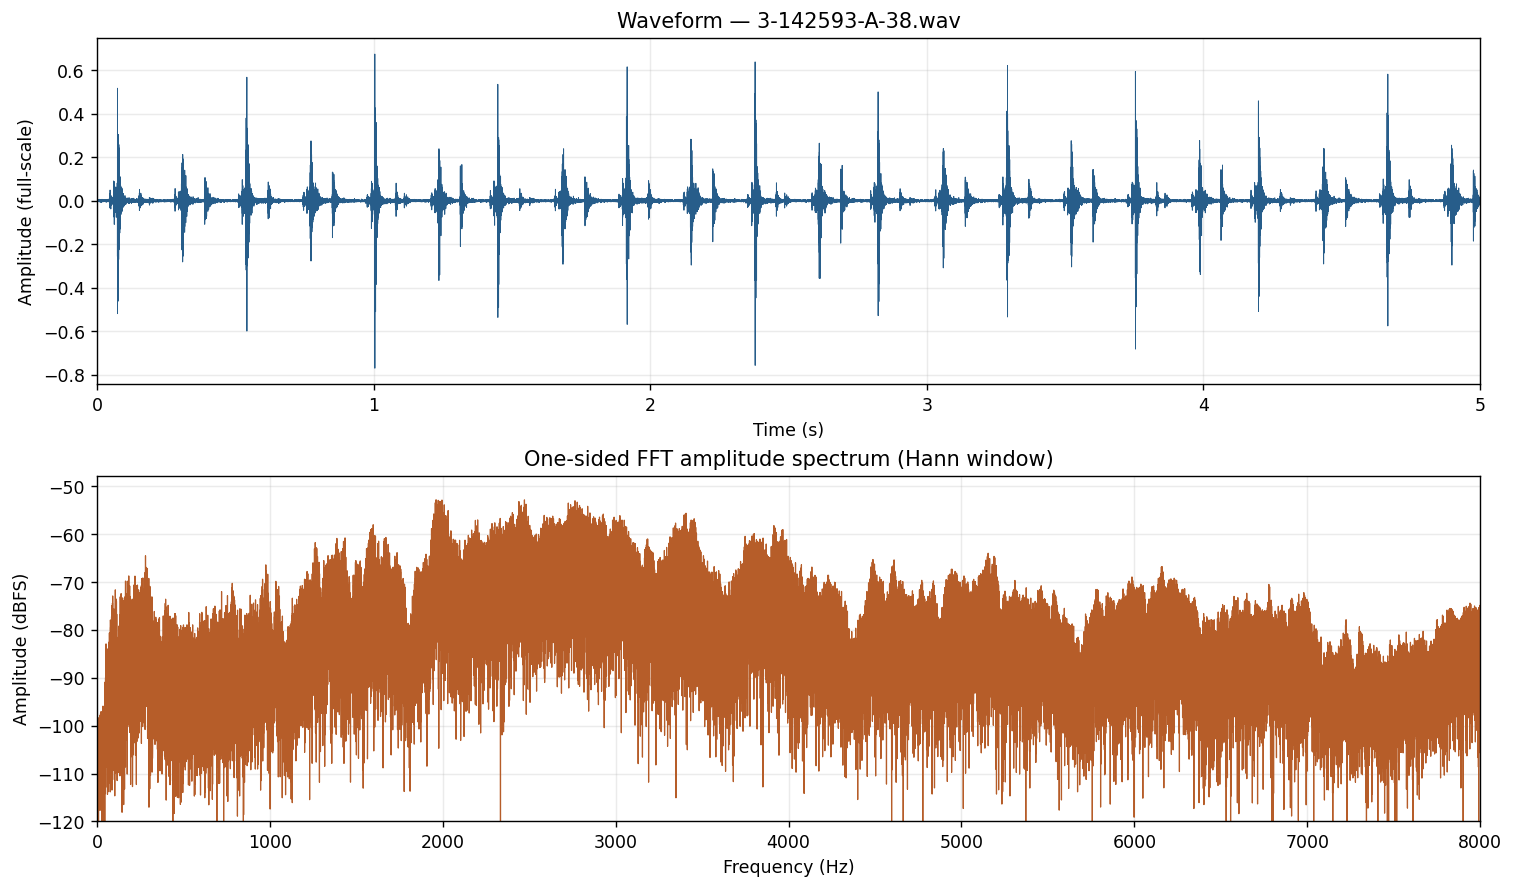

In [3]:
time_axis = np.arange(len(y)) / TARGET_SR
hann = signal.windows.hann(len(y), sym=False)
fft_amp = 2.0 * np.abs(np.fft.rfft(y * hann)) / np.sum(hann)
fft_amp[0] *= 0.5
freq_axis = np.fft.rfftfreq(len(y), d=1 / TARGET_SR)
fft_db = 20 * np.log10(np.maximum(fft_amp, 1e-8))

fig, ax = plt.subplots(2, 1, figsize=(12, 7), layout='constrained')
ax[0].plot(time_axis, y, linewidth=0.55, color='#275D8A')
ax[0].set(title=f'Waveform — {audio_path.name}', xlabel='Time (s)', ylabel='Amplitude (full-scale)')
ax[0].set_xlim(0, duration)
ax[0].grid(alpha=0.25)

ax[1].plot(freq_axis, fft_db, linewidth=0.7, color='#B65D29')
ax[1].set(title='One-sided FFT amplitude spectrum (Hann window)', xlabel='Frequency (Hz)', ylabel='Amplitude (dBFS)')
ax[1].set_xlim(0, TARGET_SR / 2)
ax[1].set_ylim(max(-120, np.max(fft_db)-95), np.max(fft_db)+5)
ax[1].grid(alpha=0.25)

fig.savefig(RESULTS_DIR / '01_waveform_and_spectrum.png', dpi=180)
plt.show()


## 2. Spectrograms: only the window length changes

Both STFTs use the same 16 kHz waveform, 160-sample hop, Hann window, zero padding at the boundaries, and identical display scales. The longer window improves **frequency resolution**, but it spreads short events across more time. A shorter window localizes fast changes better but gives less precise frequency detail.


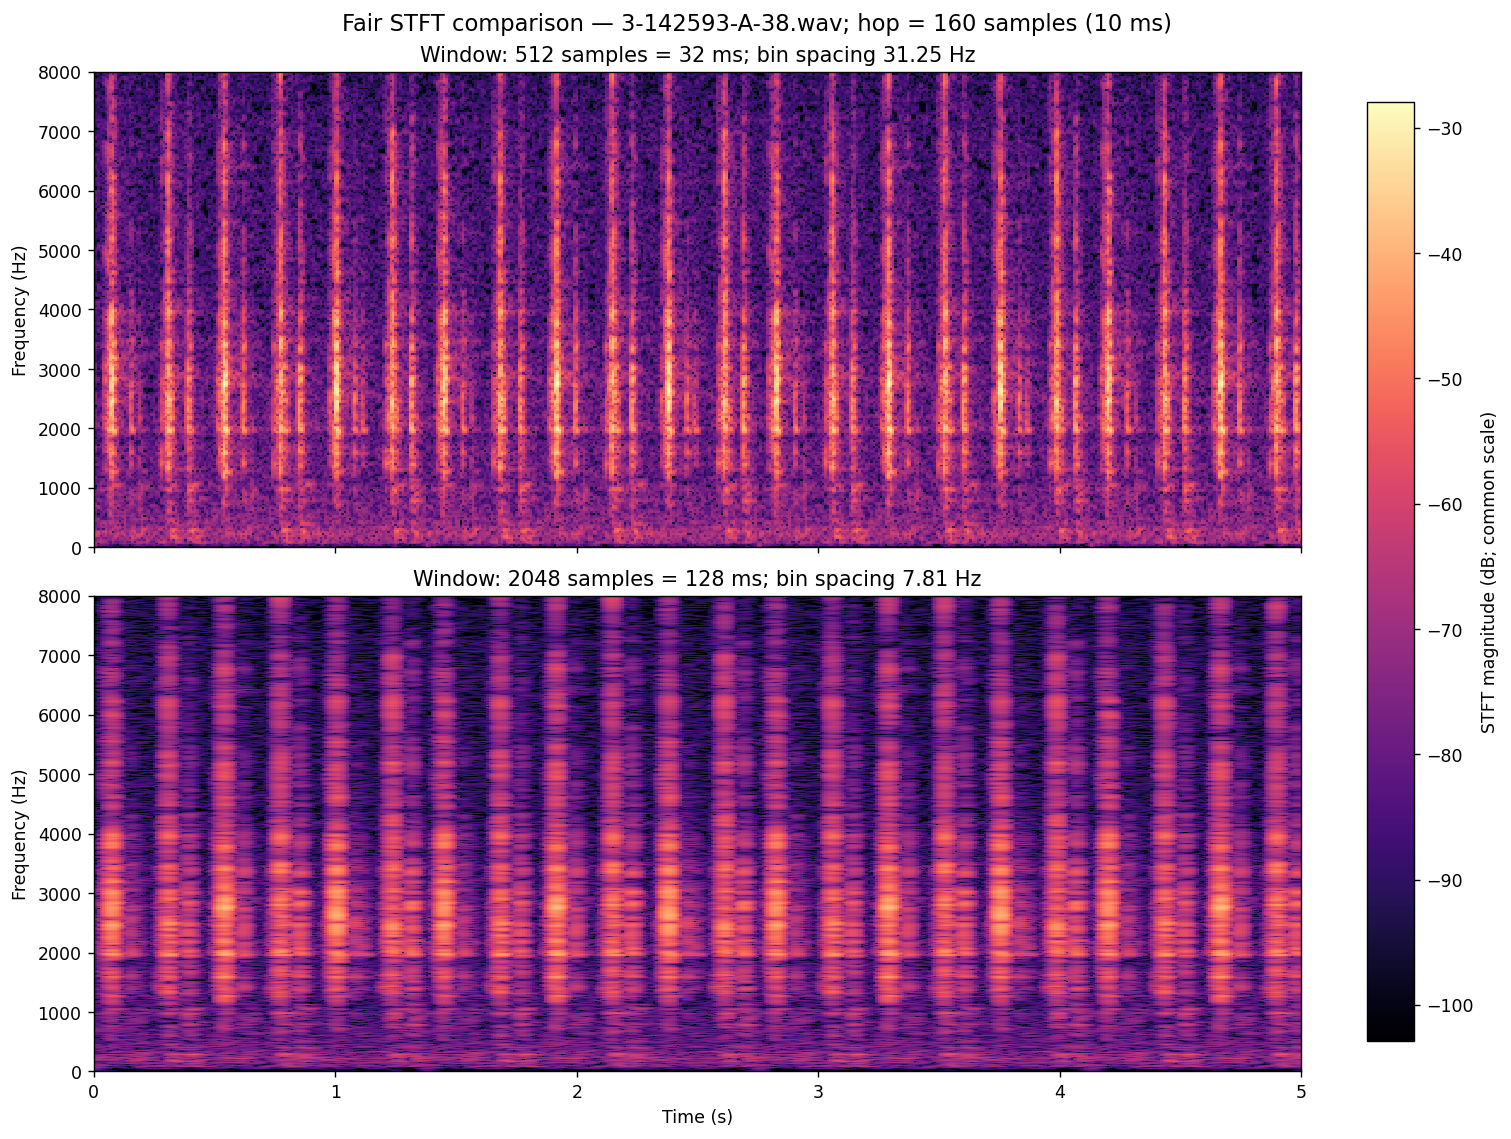

Window 512: 32 ms; frequency bin spacing 31.25 Hz; hop 10 ms
Window 2048: 128 ms; frequency bin spacing 7.8125 Hz; hop 10 ms


In [4]:
def compute_stft(window_length):
    frequencies, times, z = signal.stft(
        y, fs=TARGET_SR, window='hann', nperseg=window_length,
        noverlap=window_length-HOP, nfft=window_length,
        detrend=False, return_onesided=True,
        boundary='zeros', padded=True,
    )
    return frequencies, times, 20*np.log10(np.maximum(np.abs(z), 1e-8))

spec = {length: compute_stft(length) for length in WINDOWS}
shared_max = max(np.max(spec[length][2]) for length in WINDOWS)
shared_min = shared_max - 75

fig, axs = plt.subplots(2, 1, figsize=(12, 9), sharex=True, layout='constrained')
for axis, length in zip(axs, WINDOWS):
    f, t, db = spec[length]
    im = axis.pcolormesh(t, f, db, cmap='magma', shading='auto', vmin=shared_min, vmax=shared_max)
    axis.set(title=f'Window: {length} samples = {1e3*length/TARGET_SR:.0f} ms; bin spacing {TARGET_SR/length:.2f} Hz',
             ylabel='Frequency (Hz)', ylim=(0, TARGET_SR / 2), xlim=(0, duration))
axs[-1].set_xlabel('Time (s)')
fig.colorbar(im, ax=list(axs), label='STFT magnitude (dB; common scale)', shrink=0.94)
fig.suptitle(f'Fair STFT comparison — {audio_path.name}; hop = {HOP} samples (10 ms)', fontsize=13)
fig.savefig(RESULTS_DIR / '02_spectrograms_512_vs_2048.png', dpi=180)
plt.show()

print('Window 512: 32 ms; frequency bin spacing 31.25 Hz; hop 10 ms')
print('Window 2048: 128 ms; frequency bin spacing 7.8125 Hz; hop 10 ms')


## 3. Relevant interval, repeating attacks, and frequency region

To avoid cherry-picking, the code locates the **highest-RMS 0.40-second interval**. Within that interval it finds the largest Hann-windowed FFT peak above 50 Hz and marks a 400-Hz-wide region around the peak. It also counts peaks in the 20-ms RMS envelope, sampled every 10 ms, using fixed prominence and distance rules. These are reproducible **descriptive measurements** rather than ground-truth click timestamps or proof of a physical resonance.

If listening suggests a more relevant interval or frequency band, set the optional overrides below and explain why.


Chosen time interval: 2.100–2.500 s
Peak frequency inside interval: 3022.5 Hz
Chosen frequency region: 2822.5–3222.5 Hz
RMS-envelope attacks detected: 22
Median measured attack interval: 0.230 s


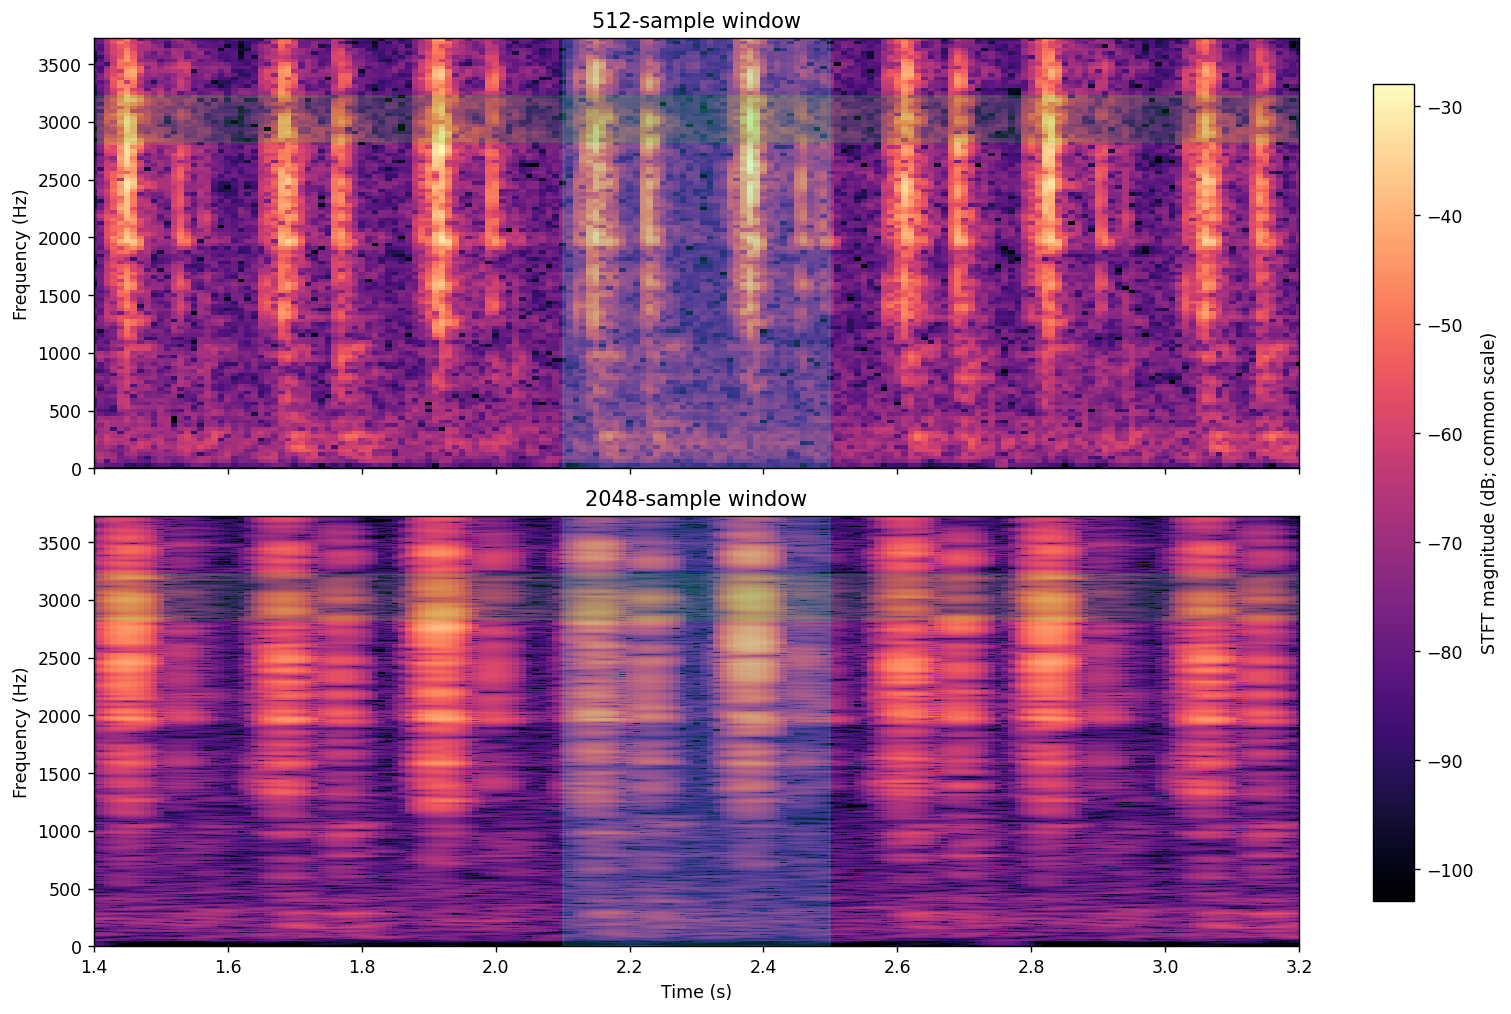

In [5]:
MANUAL_INTERVAL_S = None     # Example: (1.2, 1.6), or leave None for automatic interval
MANUAL_FREQUENCY_HZ = None   # Example: (400, 1400), or leave None for automatic peak band

segment_samples = min(int(0.4 * TARGET_SR), len(y))
step_samples = int(0.1 * TARGET_SR)
starts = np.arange(0, len(y) - segment_samples + 1, step_samples)
rms = np.array([np.sqrt(np.mean(y[s:s+segment_samples]**2)) for s in starts])
chosen_start = int(starts[np.argmax(rms)])
start_s, end_s = chosen_start / TARGET_SR, (chosen_start+segment_samples) / TARGET_SR
if MANUAL_INTERVAL_S is not None:
    start_s, end_s = map(float, MANUAL_INTERVAL_S)
if not (0 <= start_s < end_s <= duration):
    raise ValueError('The chosen interval must lie within the recording.')

excerpt = y[int(start_s*TARGET_SR):int(end_s*TARGET_SR)]
freqs_excerpt = np.fft.rfftfreq(len(excerpt), d=1/TARGET_SR)
power_excerpt = np.abs(np.fft.rfft(excerpt * signal.windows.hann(len(excerpt), sym=False)))**2
valid = (freqs_excerpt >= 50) & (freqs_excerpt <= TARGET_SR/2)
peak_frequency = float(freqs_excerpt[valid][np.argmax(power_excerpt[valid])])
band_low, band_high = max(0, peak_frequency - 200), min(TARGET_SR/2, peak_frequency + 200)
if MANUAL_FREQUENCY_HZ is not None:
    band_low, band_high = map(float, MANUAL_FREQUENCY_HZ)
if not (0 <= band_low < band_high <= TARGET_SR/2):
    raise ValueError('The selected frequency region must be within 0 to 8,000 Hz.')

print(f'Chosen time interval: {start_s:.3f}–{end_s:.3f} s')
print(f'Peak frequency inside interval: {peak_frequency:.1f} Hz')
print(f'Chosen frequency region: {band_low:.1f}–{band_high:.1f} Hz')

# Describe repetitive amplitude attacks from the 20-ms RMS envelope.
energy_frame = int(0.020 * TARGET_SR)
energy_hop = HOP
energy_starts = np.arange(0, len(y)-energy_frame+1, energy_hop)
energy_rms = np.array([np.sqrt(np.mean(y[s:s+energy_frame]**2)) for s in energy_starts])
prominence = max(0.8*np.std(energy_rms), 0.08*np.max(energy_rms))
attack_peaks, _ = signal.find_peaks(
    energy_rms, distance=int(0.18*TARGET_SR/energy_hop), prominence=prominence
)
median_attack_interval_s = float(np.median(np.diff(attack_peaks))*energy_hop/TARGET_SR)
print(f'RMS-envelope attacks detected: {len(attack_peaks)}')
print(f'Median measured attack interval: {median_attack_interval_s:.3f} s')
display(Audio(excerpt, rate=TARGET_SR))

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True, layout='constrained')
for axis, length in zip(ax, WINDOWS):
    f, t, db = spec[length]
    im = axis.pcolormesh(t, f, db, cmap='magma', shading='auto', vmin=shared_min, vmax=shared_max)
    axis.axvspan(start_s, end_s, color='cyan', alpha=0.16)
    axis.axhspan(band_low, band_high, color='lime', alpha=0.12)
    axis.set(ylabel='Frequency (Hz)', title=f'{length}-sample window', ylim=(0, min(8000, max(3000, band_high+500))))
ax[1].set(xlabel='Time (s)', xlim=(max(0,start_s-0.7), min(duration, end_s+0.7)))
fig.colorbar(im, ax=list(ax), label='STFT magnitude (dB; common scale)', shrink=0.9)
fig.savefig(RESULTS_DIR / '03_selected_time_frequency_region.png', dpi=180)
plt.show()


## 4. Results table and interpretation

The nominal window duration and frequency-bin spacing depend on sample rate and window size; the **hop remains 10 ms** in both cases. A dense hop is not the same as true time resolution: the 2048-sample window still combines roughly 128 ms of sound in each frame. The comparison describes **one clip** and **one STFT configuration**, so it cannot establish the best setting for all environmental sounds.


In [6]:
import csv

rows = [
    {'window_samples': length,
     'window_duration_ms': length/TARGET_SR*1e3,
     'frequency_bin_spacing_hz': TARGET_SR/length,
     'hop_samples': HOP,
     'hop_ms': HOP/TARGET_SR*1e3}
    for length in WINDOWS
]

with (RESULTS_DIR / 'comparison.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

meta = {
    'source_filename': audio_path.name, 'source_sha256': audio_sha256,
    'original_sampling_rate': str(original_sr), 'original_channels': str(channels),
    'analysis_sampling_rate_hz': TARGET_SR, 'duration_s': duration,
    'chosen_interval_s': [start_s, end_s],
    'fft_peak_frequency_hz': peak_frequency,
    'chosen_frequency_region_hz': [band_low, band_high],
    'rms_envelope_attack_count': int(len(attack_peaks)),
    'median_rms_attack_interval_s': median_attack_interval_s,
    'interval_selection': 'manual' if MANUAL_INTERVAL_S else 'max RMS 0.40 s',
    'frequency_selection': 'manual' if MANUAL_FREQUENCY_HZ else 'peak ±200 Hz',
    'window_function': 'Hann', 'hop_samples': HOP,
}
(RESULTS_DIR / 'recording_metadata.json').write_text(json.dumps(meta, indent=2, ensure_ascii=False)+'\n', encoding='utf-8')

print('Saved files:')
for file in sorted(RESULTS_DIR.glob('*')):
    if file.is_file():
        print(' -', file)


Saved files:
 - /workspace/scratch/e52a09c93d5a/audio_experiment_option_c/results/.gitkeep
 - /workspace/scratch/e52a09c93d5a/audio_experiment_option_c/results/01_waveform_and_spectrum.png
 - /workspace/scratch/e52a09c93d5a/audio_experiment_option_c/results/02_spectrograms_512_vs_2048.png
 - /workspace/scratch/e52a09c93d5a/audio_experiment_option_c/results/03_selected_time_frequency_region.png
 - /workspace/scratch/e52a09c93d5a/audio_experiment_option_c/results/comparison.csv
 - /workspace/scratch/e52a09c93d5a/audio_experiment_option_c/results/recording_metadata.json


## 5. Observations, interpretation, conclusion, and limitations

**Listening and signal evidence.** The course manifest labels this five-second recording `clock_tick`. The notebook embeds both the full WAV and a selected excerpt for listening. The waveform shows short, discrete attacks that repeat throughout the clip, with quieter gaps between them. A fixed RMS-envelope detector identifies **22 prominent attacks**, separated by a median of approximately **0.23 seconds**. Attack heights differ slightly. The waveform and course label are consistent with mechanical ticking; the whole-file spectrum spreads energy over a broad band instead of one pure pitch.

**Relevant time and frequency region.** The highest-RMS 0.40-second interval is **2.10–2.50 s**. Within it, the strongest FFT peak is approximately **3022.5 Hz**; the highlighted band is **2822.5–3222.5 Hz**. The selected-region figure reveals attacks containing energy around 3 kHz. The 400-Hz band is an illustrative spectral region, not the entire tick spectrum: short transients contain broadband energy beyond it.

**Window comparison.** At 16 kHz, a **512-sample** Hann window spans **32 ms**, with **31.25 Hz** FFT-bin spacing. Brief ticks therefore appear as comparatively narrow vertical stripes. A **2048-sample** window spans **128 ms** with **7.8125 Hz** bin spacing: frequency structure is more detailed, but each click spreads more broadly across time. Both use the same waveform, the same **160-sample (10-ms) hop**, and the same dB colour scale. The resulting time-frequency trade-off is therefore caused by the window length in this controlled comparison.

**Preferred setting.** For this clock-tick clip I prefer **512 samples**. Locating the short, repeated clicks in time is more useful for this question than separating very close frequency components. The 2048-sample view can still help reveal detailed frequency bands within an individual attack.

**Limitations.** This is one **five-second** ESC-50 recording, not a representative evaluation across sound environments. RMS peak detection depends on thresholds, and the counted peaks are not hand-verified event annotations. Resampling to 16 kHz excludes frequencies above **8 kHz**, while the dB colour limits influence visibility. A spectrogram describes time-frequency energy but cannot, by itself, prove that a particular physical clock produced the clicks.

**Audio attribution.** `3-142593-A-38.wav`: ESC-50 class `clock_tick`; derived from *Ticking.aif* by **timgormly**, [Freesound recording 142593](https://freesound.org/people/timgormly/sounds/142593/) (**CC0**). The ESC-50 classroom subset is described as **CC BY-NC 3.0**. See `attribution/ESC50_LICENSE.txt` and `attribution/course_manifest.csv`.
